In [1]:
import numpy as np
import matplotlib.pyplot as plt
import wildfire
from wildfire.utils.functions import G
from wildfire.utils import plots, gradient
from optimizer import optimizer_object

import scipy.optimize as opt

%load_ext autoreload
%autoreload 2

gamma = 10 | Nt = 162 | t_lims = (np.float64(0.0), np.float64(13.0))
J_opt/J_init = 0.821 | J_opt/J_no_drop = 0.793 | J_no_drop = 58276, J_init = 56290, J_opt = 46207
asset 1 lost: 88% (no drop) -> 74% (optimized) | asset 2 lost: 9% -> 3%
iterations = 18, status = 0, x_opt = [-14.34 -24.55   0.83   0.     3.81  16.1    0.79   3.5 ]


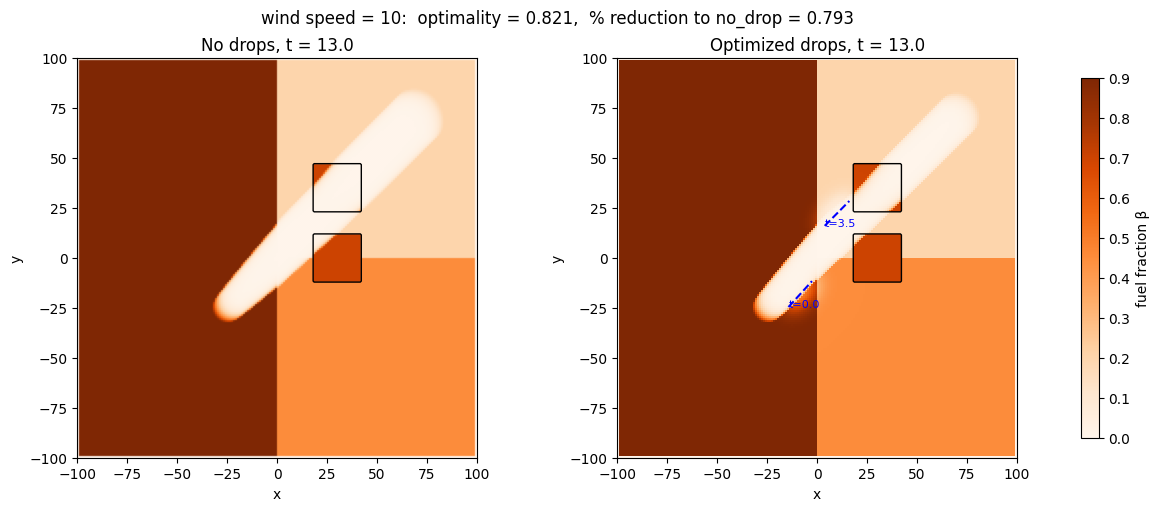

In [25]:
import numpy as np
import matplotlib.pyplot as plt

gamma = 10
file_name = f"data/optimization_runs_slsqp/gamma={gamma}.npz"     
file_data = np.load(file_name)

# --- summary ---
J_none, J_init, J_opt = float(file_data["no_drop_obj"]), float(file_data["init_obj"]), float(file_data["drop_obj"])
print(f"gamma = {int(file_data['gamma'])} | Nt = {int(file_data['Nt'])} | t_lims = {tuple(file_data['t_lims'])}")
print(f"J_opt/J_init = {J_opt / J_init:.3f} | J_opt/J_no_drop = {J_opt / J_none:.3f} | "
      f"J_no_drop = {J_none:.0f}, J_init = {J_init:.0f}, J_opt = {J_opt:.0f}")
print(f"asset 1 lost: {float(file_data['no_drop_A1_lost']):.0%} (no drop) -> {float(file_data['drop_A1_lost']):.0%} (optimized) | "
      f"asset 2 lost: {float(file_data['no_drop_A2_lost']):.0%} -> {float(file_data['drop_A2_lost']):.0%}")
print(f"iterations = {int(file_data['nit'])}, status = {int(file_data['status'])}, "
      f"x_opt = {np.round(file_data['x_opt'], 2)}")

# --- final fuel fields side by side ---
x, y = file_data["x"], file_data["y"]
ext = [x[0], x[-1], y[0], y[-1]]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, key, title in zip(axes, ["no_drop_B", "drop_B"], ["No drops", "Optimized drops"]):
    im = ax.imshow(file_data[key][-1], origin="lower", extent=ext, cmap="Oranges", vmin=0, vmax=0.9)
    for m in ("asset1", "asset2"):                               # asset outlines
        ax.contour(x, y, file_data[m].astype(float), levels=[0.5], colors="k", linewidths=1)
    ax.set_title(f"{title}, t = {file_data['t'][-1]:.1f}")
    ax.set_xlabel("x"); ax.set_ylabel("y")

# drop paths of the optimized run (plane speed v = 5, drop duration T = 3.5)
v, T = 5, 3.5
for xs, ys, th, ts in file_data["x_opt"].reshape(-1, 4):
    axes[1].plot([xs, xs + v * T * np.cos(th)], [ys, ys + v * T * np.sin(th)], "b--", lw=1.5)
    axes[1].annotate(f"t={ts:.1f}", (xs, ys), color="b", fontsize=8)

fig.colorbar(im, ax=axes, location="right", shrink=0.9, label="fuel fraction β")
fig.suptitle(f"wind speed = {int(file_data['gamma'])}:  optimality = {J_opt / J_init:.3f},  % reduction to no_drop = {J_opt / J_none:.3f}")
plt.show()

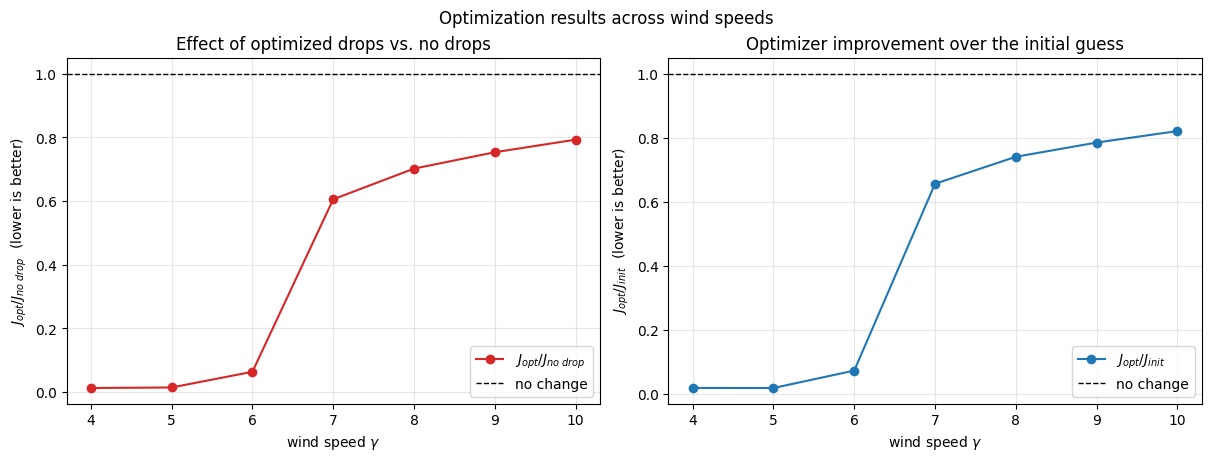

In [19]:
gammas = [4, 5, 6, 7, 8, 9, 10]
protection, optimality = [], []

for gamma in gammas:
    d = np.load(f"data/optimization_runs_slsqp/gamma={gamma}.npz")
    J_none, J_init, J_opt = float(d["no_drop_obj"]), float(d["init_obj"]), float(d["drop_obj"])
    protection.append(J_opt / J_none)      # < 1: optimized drops beat no drops
    optimality.append(J_opt / J_init)      # < 1: optimizer improved on the initial guess

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

ax[0].plot(gammas, protection, "o-", color="tab:red", label=r"$J_{opt} / J_{no\ drop}$")
ax[0].set_title("Effect of optimized drops vs. no drops")
ax[0].set_ylabel(r"$J_{opt} / J_{no\ drop}$  (lower is better)")

ax[1].plot(gammas, optimality, "o-", color="tab:blue", label=r"$J_{opt} / J_{init}$")
ax[1].set_title("Optimizer improvement over the initial guess")
ax[1].set_ylabel(r"$J_{opt} / J_{init}$  (lower is better)")

for a in ax:
    a.axhline(1.0, color="k", ls="--", lw=1, label="no change")
    a.set_xlabel(r"wind speed $\gamma$")
    a.set_xticks(gammas)
    a.grid(alpha=0.3)
    a.legend()

fig.suptitle("Optimization results across wind speeds")
plt.show()